# **Dataset Visualization & Plots**

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from IPython.display import display

# Load the cleaned dataset
df = pd.read_csv("../data/iot23_cleaned.csv")

# Output directory
output_dir = Path("iot23_visualizations")
output_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (23145, 24)

Columns:
['ts', 'uid', 'id_orig_h', 'id_orig_p', 'id_resp_h', 'id_resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'local_orig', 'local_resp', 'missed_bytes', 'history', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'tunnel_parents', 'label', 'detailed_label', 'target']


# Plot 1: Class Distribution

**Why is it used?**

The class distribution plot is used to examine the number of records belonging to each traffic label in the IoT-23 dataset. It helps determine whether the dataset is balanced or imbalanced. Identifying class imbalance is important because a model may favor the majority class during training, potentially reducing its ability to detect less frequent classes.


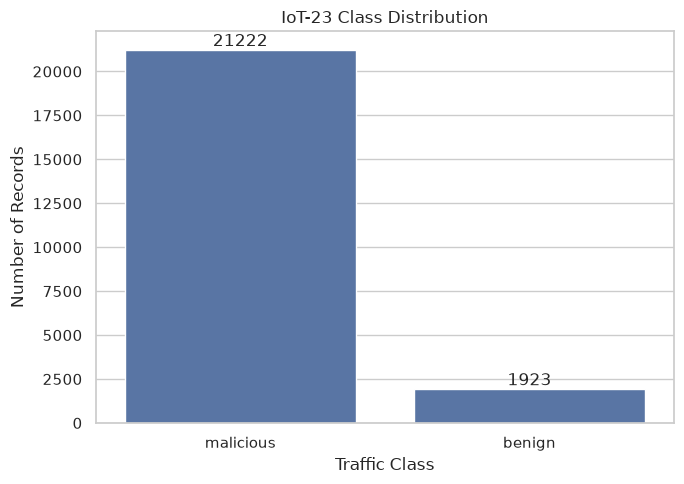

In [44]:

plt.figure(figsize=(7, 5))

class_counts = df["label"].value_counts()

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

ax.set_title("IoT-23 Class Distribution")
ax.set_xlabel("Traffic Class")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.savefig(output_dir / "01_class_distribution.png", dpi=300)
plt.show()
plt.close()


**Interpretation of Results**

The height of each bar represents the number of records associated with a particular label. A significantly taller bar indicates that the corresponding class contains more records than the others. If the class counts differ substantially, the dataset may suffer from class imbalance. If the counts are relatively similar, the distribution is more balanced. This analysis helps assess the dataset's suitability for training and evaluating a GNN model.

# Plot 2: Network Traffic Feature Distributions

**Why is it used?**

This plot examines the distributions of five numerical features: orig_pkts, resp_pkts, orig_ip_bytes, resp_ip_bytes, and duration. It helps identify common traffic patterns, understand the spread of numerical values, and detect highly skewed distributions. The logarithmic transformation, log(1 + x), is applied to make large differences between values easier to visualize.


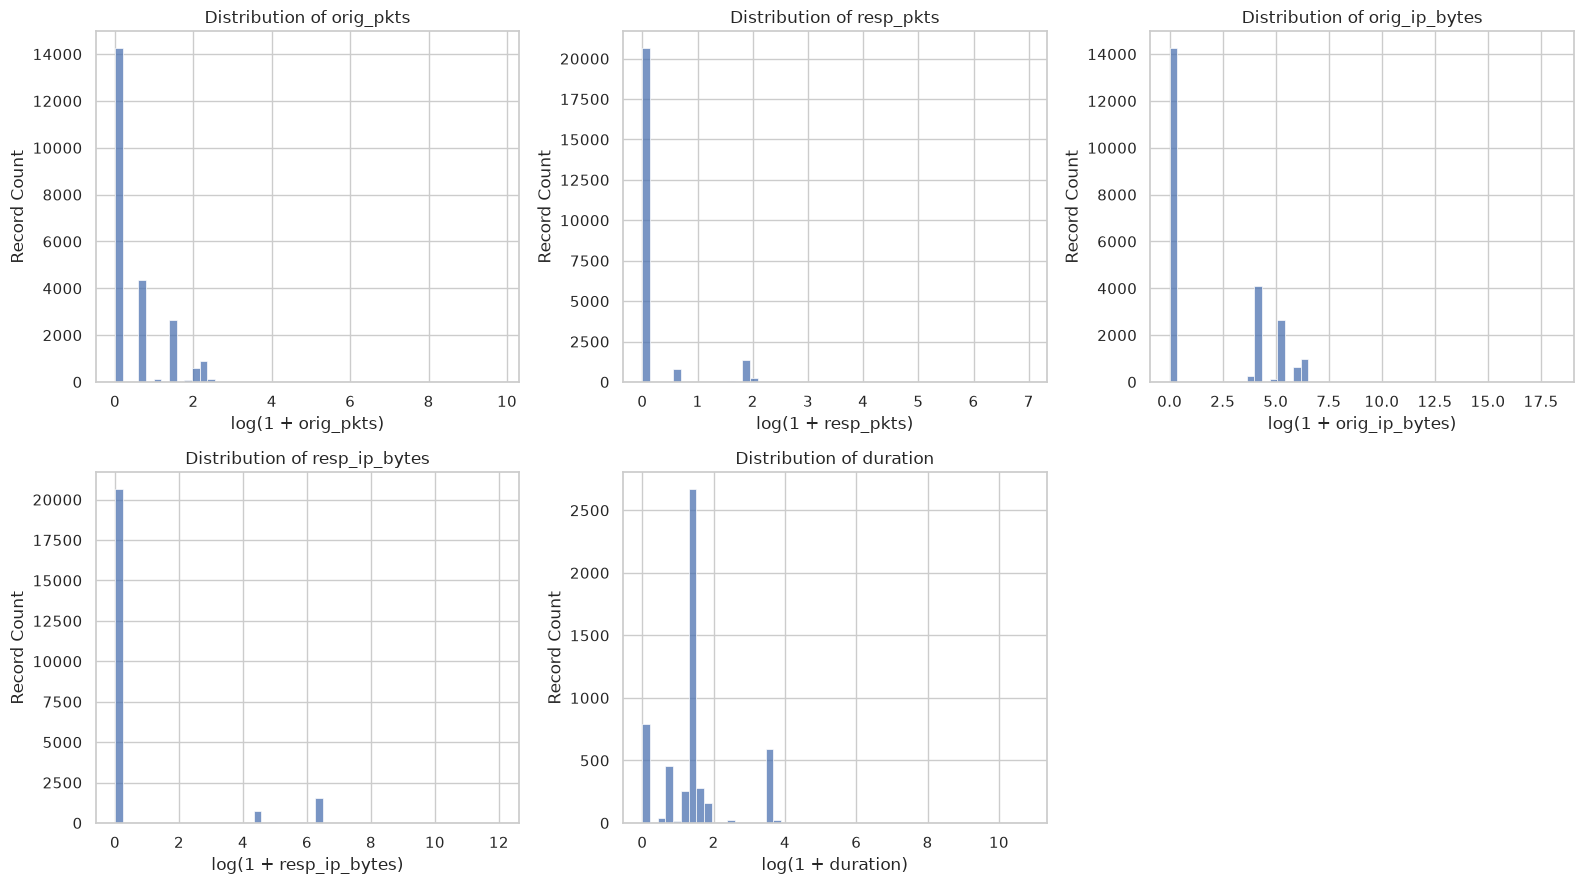

In [45]:


numeric_cols = [
    "orig_pkts",
    "resp_pkts",
    "orig_ip_bytes",
    "resp_ip_bytes",
    "duration"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    values = values[np.isfinite(values)]

    sns.histplot(
        np.log1p(values[values >= 0]),
        bins=50,
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_ylabel("Record Count")

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(
    output_dir / "02_feature_distributions.png",
    dpi=300
)
plt.show()
plt.close()


**Interpretation of Results**

If most observations are concentrated toward the left side of a histogram, the feature generally contains many low values. A long tail extending toward the right indicates that some network connections have substantially higher values than most others. Differences between the distributions reveal variations in packet counts, transmitted data volumes, and connection durations.

These patterns help characterize network traffic and identify features that may be useful for distinguishing normal traffic from suspicious activity. However, the distributions alone cannot establish whether a particular pattern is malicious.

# Plot 3: Top 15 Network Protocols

**Why is it used?**

The protocol distribution plot identifies the 15 most frequently occurring network protocols in the dataset using the proto column. It provides an overview of the protocols represented in the observed network traffic and helps identify which protocols dominate the dataset.


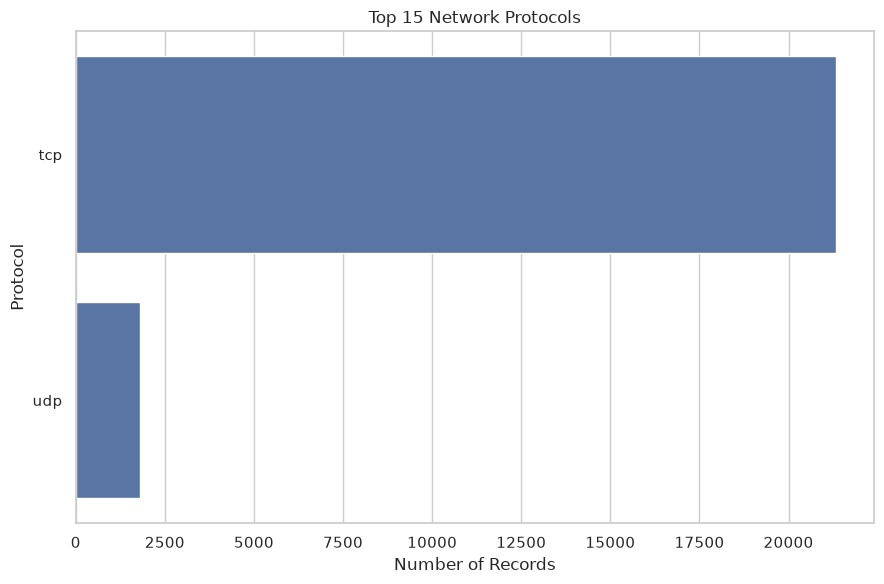

In [46]:

plt.figure(figsize=(9, 6))

protocol_counts = df["proto"].value_counts().head(15)

ax = sns.barplot(
    x=protocol_counts.values,
    y=protocol_counts.index
)

ax.set_title("Top 15 Network Protocols")
ax.set_xlabel("Number of Records")
ax.set_ylabel("Protocol")

plt.tight_layout()
plt.savefig(
    output_dir / "03_protocol_distribution.png",
    dpi=300
)
plt.show()
plt.close()


**Interpretation of Results**

Each horizontal bar represents a protocol, and its length indicates the number of records associated with that protocol. The longest bar corresponds to the most frequent protocol among the displayed top 15. Shorter bars indicate protocols with fewer records.

A highly concentrated distribution suggests that a small number of protocols account for a large proportion of the observed connections. A more distributed pattern indicates greater protocol diversity. These findings help describe the dataset's traffic composition, although protocol frequency alone does not determine whether traffic is normal or malicious.


# Plot 4: Traffic Features by Class

**Why is it used?**

This plot compares the distributions of numerical traffic features across the different labels in the label column. Boxplots summarize the median, interquartile range, and spread of each feature within each class. The comparison helps determine whether normal and suspicious traffic exhibit different statistical characteristics.


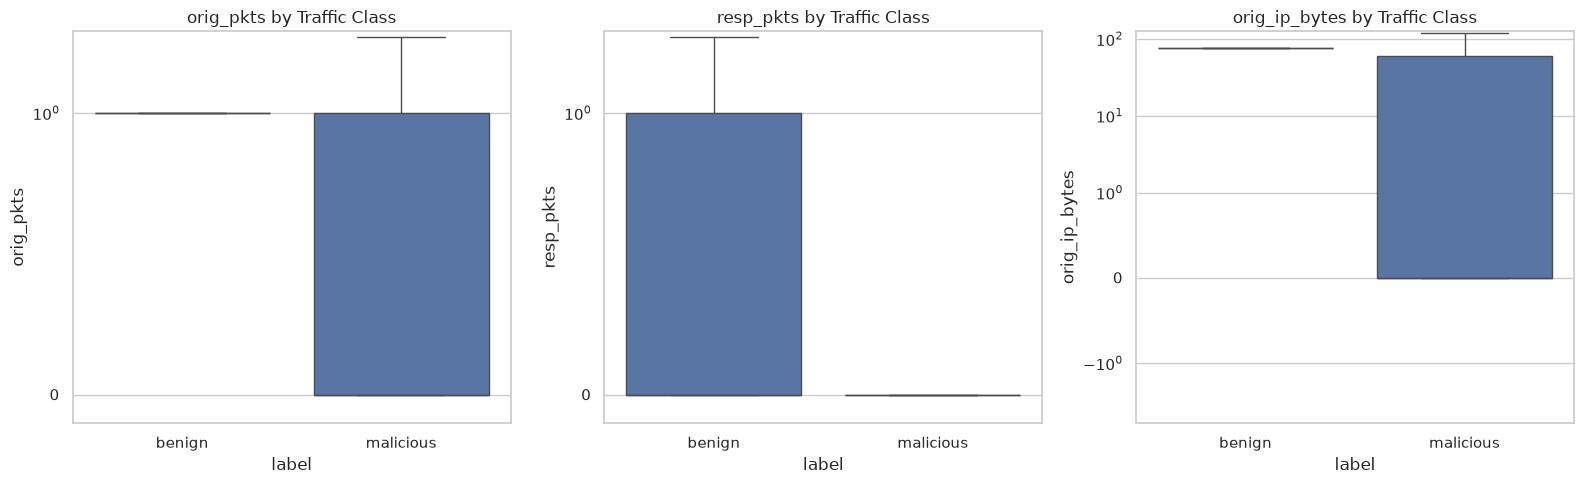

In [47]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=df,
        x="label",
        y=col,
        showfliers=False,
        ax=ax
    )
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(f"{col} by Traffic Class")

plt.tight_layout()
plt.savefig(output_dir / "04_class_comparison.png", dpi=300)
plt.show()
plt.close()


**Interpretation of Results**

The median line inside each box represents the central value of a feature for a particular class. The box represents the interquartile range, covering the middle 50% of observations. Wider boxes indicate greater variability in the central portion of the data.

If the boxes and medians differ substantially between classes, the feature may help distinguish their traffic patterns. If the distributions overlap considerably, that feature alone may provide limited separation. The showfliers=False setting hides individual outlier points, while the symmetric logarithmic y-axis helps display values spanning different scales.

These comparisons can help identify potentially informative features for the GNN model, but they do not prove that a feature will improve model performance.

# Plot 5: Outlier Visualization

**Why is it used?**

The outlier visualization uses boxplots to examine unusually low or high values in the numerical traffic features. Outliers may represent rare network behavior, unusually large data transfers, long connections, or measurement irregularities. Identifying them helps understand the variability of the dataset and determine whether further investigation is necessary.


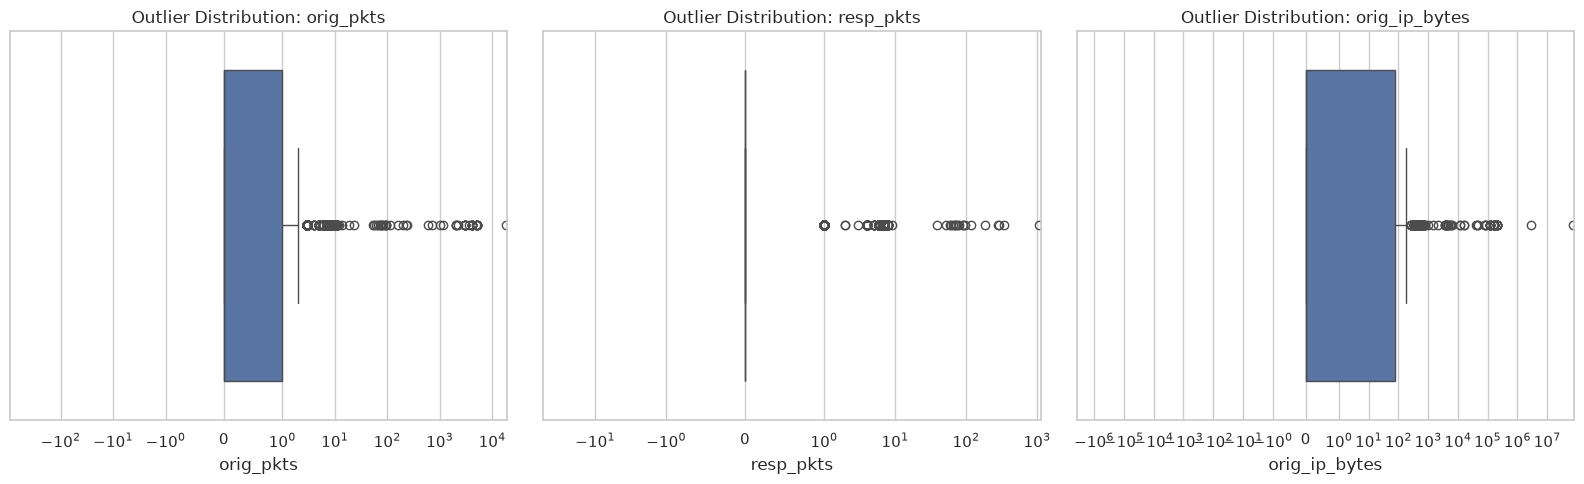

In [48]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(f"Outlier Distribution: {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.savefig(output_dir / "05_outlier_analysis.png", dpi=300)
plt.show()
plt.close()


**Interpretation of Results**

In a standard boxplot, observations beyond the whiskers are displayed as individual points and are commonly treated as potential outliers under the 1.5 × IQR rule. A large number of such points indicates that the feature contains many observations outside its central range.

In this code, the horizontal axis uses a symmetric logarithmic scale, allowing both zero and large positive values to be displayed. Outliers are not necessarily errors or malicious activity; unusual network connections may be legitimate. Therefore, they should be investigated rather than automatically removed.

Important technical note: The current plot displays boxplots but does not calculate or report the number or percentage of outliers. Those values would require an additional statistical calculation.

# Plot 6: Traffic Feature Correlation Heatmap 

**Why is it used?**

The correlation heatmap examines the pairwise linear relationships between the five numerical traffic features. It helps identify features that tend to increase or decrease together and highlights potential redundancy between variables.

The Pearson correlation coefficient ranges from -1 to +1:

- +1: Perfect positive linear correlation.

- 0: No linear correlation.

- -1: Perfect negative linear correlation.



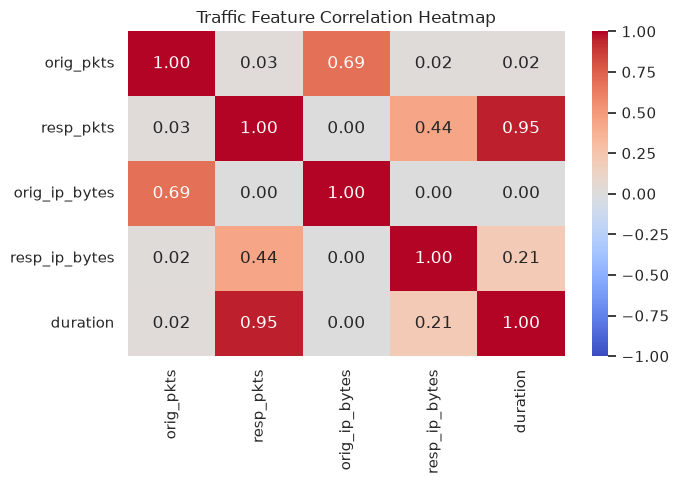

In [49]:

correlation = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Traffic Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig(output_dir / "06_correlation_heatmap.png", dpi=300)
plt.show()
plt.close()

**Interpretation of Results**

Positive correlation values indicate that two features tend to increase together. Negative values indicate that higher values of one feature tend to be associated with lower values of the other. Values close to zero indicate weak linear relationships.

Strong correlations between packet counts and byte counts, for example, may indicate that these traffic measurements capture related aspects of network activity. Such relationships can help explain the dataset's feature structure and inform feature selection.

However, correlation does not establish causation, and a weak Pearson correlation does not rule out a nonlinear relationship. This plot also does not directly measure the relationship between the features and the traffic labels.

# Plot 7: Median Feature Comparison by Class

**Why is it used?**

This plot compares the median values of the five numerical features across the different traffic classes. The median is less sensitive to extreme values than the mean, making it useful for comparing typical traffic behavior in datasets with skewed distributions.



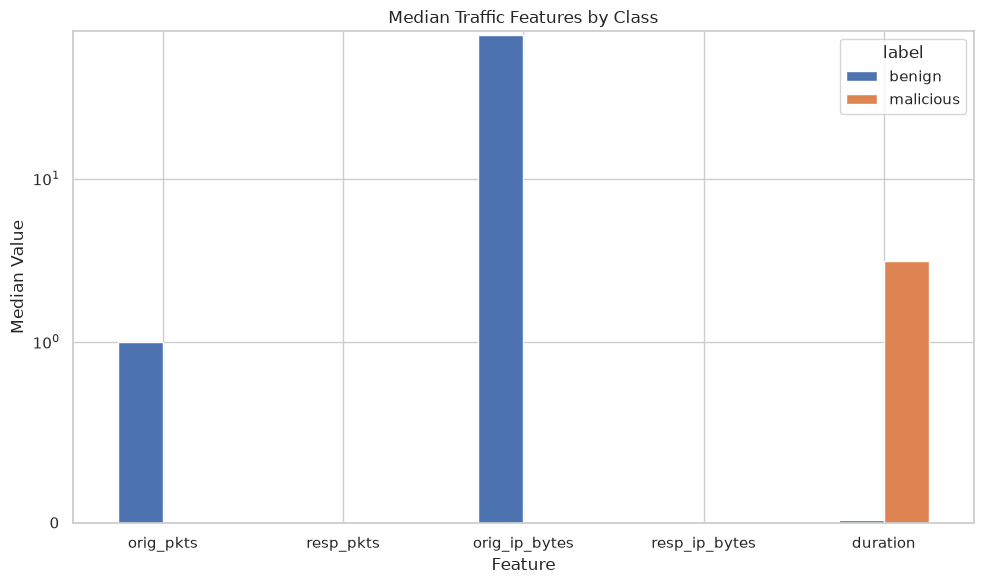

In [50]:
medians = df.groupby("label")[numeric_cols].median().T

ax = medians.plot(kind="bar", figsize=(10, 6))

ax.set_title("Median Traffic Features by Class")
ax.set_xlabel("Feature")
ax.set_ylabel("Median Value")
ax.set_yscale("symlog", linthresh=1)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(output_dir / "07_class_median_comparison.png", dpi=300)
plt.show()
plt.close()



**Interpretation of Results**

Each feature has a separate group of bars, with each bar representing the median value for a particular class. Higher bars indicate higher median values for that feature and class.

If the median packet counts, byte volumes, or connection durations differ between classes, the corresponding features may capture meaningful differences in typical traffic behavior. Similar medians suggest that the typical values are comparable, although the classes may still differ in their variability or overall distributions.

The symmetric logarithmic y-axis helps display features with very different magnitudes. Since each feature has a different unit and scale, comparisons should primarily be made between classes within the same feature, rather than comparing the heights of unrelated features directly.

# **Save Results and Download ZIP**

In [51]:


import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    "iot23_visualizations",
    "zip",
    root_dir=output_dir
)

print("\nVisualization completed successfully.")
print("Records visualized:", len(df))
print("Output directory:", output_dir.resolve())
print("ZIP archive:", Path(zip_path).resolve())

display(FileLink(zip_path))



Visualization completed successfully.
Records visualized: 23145
Output directory: /workspaces/IoT_GNN/notebooks/iot23_visualizations
ZIP archive: /workspaces/IoT_GNN/notebooks/iot23_visualizations.zip


/workspaces/IoT_GNN/notebooks/iot23_visualizations.zip